# First Partial Examination, Coding Task: Missed Appointments

Vardar Health is a polyclinic in Skopje with seven departments. A patient books an appointment by phone, online, or through a referral from their family doctor, and the clinic sends a reminder by text message, calls the patient, or sends nothing. Roughly one appointment in five is missed, and a missed appointment leaves a doctor idle for the whole slot. The clinic wants to know, at the moment an appointment is booked, how likely the patient is to miss it, so that a nurse can call the patients most at risk and offer their slot to someone else when they cannot come. The appointments are synthetic and describe no real patient or clinic.

The export in `data/appointments.csv` holds one row per booked appointment, and these are its columns:

- `appointment_id`, the identifier of the appointment, `patient_id`, the identifier of the patient, and `appointment_date`, the day of the appointment,
- `department`, the department, and `booking_channel`, which is phone, online, or referral,
- `priority`, which the booking clerk sets to low, normal, or high,
- `reminder`, which is none, sms, or call,
- `lead_days`, the number of days between the booking and the appointment,
- `patient_age`, the age of the patient in years, `insurance`, which is public or private, and `distance_km`, the distance from the patient's address to the clinic in kilometres,
- `prior_visits`, the number of earlier appointments of the patient, and `prior_no_shows`, how many of them the patient missed,
- `waiting_minutes`, the minutes the patient waited at the clinic before the doctor saw them, and
- `no_show`, which is yes when the patient missed the appointment, the value a model will predict.

A call costs the clinic little, and a missed slot costs it a lot. A missed appointment that nobody called about costs 4 units, and a call to a patient who would have come anyway costs 1 unit. A call to a patient who would have missed the appointment frees the slot for another patient, so it costs nothing.

The cells that hold no request run as they are, and they hold the split, the preparations, the folds, and the cost that the requests use. Every other request needs a few lines of code at most, and no request needs the answer of another. Answer each request in the cells below it, and add as many cells as you need. The test asks for values and decisions that your notebook computes, so keep every result visible.

## Setup

Run the cells in this section before the tasks.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, LogisticRegression
from sklearn.metrics import make_scorer, mean_absolute_error, precision_score, r2_score, recall_score, roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_validate, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA = Path("data")
# Every random step uses this seed, so a rerun gives the same result.
SEED = 2026

In [14]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [15]:
# The export writes a value it does not have as a question mark.
appointments = pd.read_csv(DATA / "appointments.csv", na_values="?")
appointments.head()

,appointment_id,patient_id,appointment_date,department,booking_channel,priority,reminder,lead_days,patient_age,insurance,distance_km,prior_visits,prior_no_shows,waiting_minutes,no_show
0,500001,10066,2025-07-01,ophthalmology,phone,low,none,24,35.0,public,2.9,3,1,10.0,no
1,500002,10120,2025-07-01,cardiology,online,normal,call,36,53.0,public,6.5,1,0,NaN,yes
2,500003,10249,2025-07-01,dermatology,phone,high,sms,5,52.0,private,9.2,1,0,21.0,no
3,500004,10545,2025-07-01,orthopaedics,phone,normal,none,0,61.0,public,18.0,6,5,NaN,yes
4,500005,10601,2025-07-01,paediatrics,online,low,sms,12,7.0,public,3.6,5,0,30.0,no


## Task 1: Exploring the Appointments

### 1.1 A First Look

In [24]:
appointments.shape, appointments["patient_id"].nunique()

((1920, 15), 1150)

In [25]:
appointments.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
appointment_id,1920.0,500960.50,554.40,500001.0,500480.75,500960.5,501440.25,501920.0
patient_id,1920.0,10566.09,333.70,10000.0,10284.75,10555.5,10855.25,11149.0
lead_days,1920.0,12.24,16.13,0.0,2.00,6.0,16.00,149.0
patient_age,1787.0,52.73,25.55,1.0,38.00,54.0,71.00,92.0
distance_km,1824.0,5.43,4.45,0.4,2.58,4.2,6.80,44.0
prior_visits,1920.0,3.53,1.96,0.0,2.00,3.0,5.00,10.0
prior_no_shows,1920.0,0.76,1.10,0.0,0.00,0.0,1.00,9.0
waiting_minutes,1556.0,20.03,13.10,1.0,10.00,17.0,27.00,88.0


In [26]:
appointments.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
appointment_date,1920,450,2026-08-30,11
department,1920,7,general practice,618
booking_channel,1920,3,phone,1030
priority,1920,3,low,937
reminder,1920,3,sms,790
insurance,1920,2,public,1492
no_show,1920,2,no,1556


### 1.2 The Gaps

The table counts the missing values of each column, and the share of the appointments of each booking channel that lack the value.

In [27]:
gaps = appointments.isna().sum()
gaps = list(gaps[gaps > 0].index)
pd.concat(
    [
        appointments[gaps].isna().sum().rename("missing").to_frame().T,
        appointments[gaps].isna().groupby(appointments["booking_channel"]).mean().round(3),
    ]
)

,patient_age,distance_km,waiting_minutes
missing,133.000,96.000,364.000
online,0.203,0.056,0.189
phone,0.019,0.052,0.193
referral,0.022,0.035,0.180


In [28]:
pd.crosstab(appointments["no_show"], appointments["waiting_minutes"].isna().rename("waiting_minutes missing"))

waiting_minutes missing,False,True
no_show,,
no,1556,0
yes,0,364


### 1.3 Who Misses an Appointment

In [29]:
appointments["no_show"].value_counts(normalize=True).round(4)

no_show
no     0.8104
yes    0.1896
Name: proportion, dtype: float64

In [30]:
missed = appointments["no_show"].eq("yes")
rates = {
    column: missed.groupby(appointments[column]).mean().round(3) for column in ["department", "priority", "insurance"]
}
rates["department"].sort_values(), rates["priority"], rates["insurance"]

(department
 gynaecology         0.124
 paediatrics         0.149
 general practice    0.157
 cardiology          0.216
 orthopaedics        0.222
 dermatology         0.257
 ophthalmology       0.272
 Name: no_show, dtype: float64,
 priority
 high      0.075
 low       0.218
 normal    0.200
 Name: no_show, dtype: float64,
 insurance
 private    0.150
 public     0.201
 Name: no_show, dtype: float64)

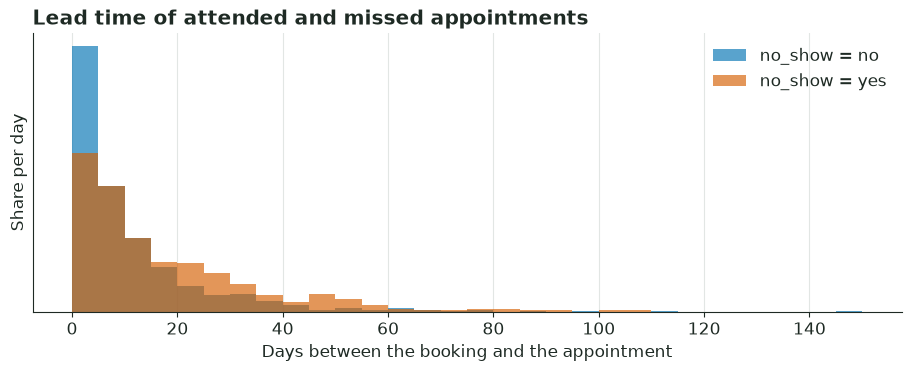

In [31]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 155, 5)
for label, colour in [("no", PALETTE[0]), ("yes", PALETTE[1])]:
    ax.hist(
        appointments.loc[appointments["no_show"] == label, "lead_days"],
        bins=bins,
        alpha=0.65,
        density=True,
        color=colour,
        label=f"no_show = {label}",
    )
ax.set(
    xlabel="Days between the booking and the appointment",
    ylabel="Share per day",
    yticks=[],
    title="Lead time of attended and missed appointments",
)
ax.legend()
plt.show()

### 1.4 Reminders

Find the share of missed appointments for each kind of reminder.

> **Question 1 (1 point).** What share of the appointments without a reminder were missed? State the answer as a proportion between 0 and 1.

In [ ]:
# Write your solution here.

### 1.5 Lead Time

Find the median lead time of the missed appointments and of the attended ones.

> **Question 2 (2 points).** What is the median number of days until the appointment for the missed appointments?

In [ ]:
# Write your solution here.

### 1.6 Earlier Missed Appointments

Find the Spearman correlation between the number of earlier missed appointments and whether the appointment was missed.

> **Question 3 (2 points).** What is the Spearman correlation coefficient between the number of earlier missed appointments and whether the appointment was missed?

In [ ]:
# Write your solution here.

## Task 2: Inference

### 2.1 Reminders and Missed Appointments

Test at the 5% level whether the share of missed appointments depends on the kind of reminder.

> **Question 4 (2 points).** What does the chi-squared test of whether the share of missed appointments depends on the kind of reminder show at the significance level of 5%?

In [5]:
# Write your solution here.
stats.chi2_contingency(pd.crosstab(appointments["no_show"], appointments["reminder"]))

Chi2ContingencyResult(statistic=np.float64(19.10920141617004), pvalue=np.float64(7.087443922726448e-05), dof=2, expected_freq=array([[316.87291667, 598.89791667, 640.22916667],
       [ 74.12708333, 140.10208333, 149.77083333]]))

### 2.2 The Mean Lead Time of Missed Appointments

Find the 95% confidence interval for the mean lead time of the missed appointments.

> **Question 5 (2 points).** What is the lower bound of the 95% confidence interval for the mean number of days until the appointment for the missed appointments?

In [6]:
# Write your solution here.
missed_appointments_table = appointments.query("no_show == 'yes'")
missed_appointments_lead_days = missed_appointments_table["lead_days"]

stats.t.interval(0.95, df=len(missed_appointments_lead_days) - 1, loc = missed_appointments_lead_days.mean(), scale=stats.sem(missed_appointments_lead_days))

(np.float64(15.459665623065964), np.float64(19.227147563747224))

### 2.3 Age

Test at the 5% level whether the mean age of the patients differs between missed and attended appointments, without assuming equal variances. Use the ages as recorded.

> **Question 6 (3 points).** What does the test without the assumption of equal variances of whether the mean age differs between missed and attended appointments show at the significance level of 5%?

In [7]:
# Write your solution here.
apointments_with_patient_age = appointments[appointments["patient_age"].isna() == False]

missed_appointments = apointments_with_patient_age.query("no_show == 'yes'")
attended_appointments = apointments_with_patient_age.query("no_show == 'no'")

welch = stats.ttest_ind(missed_appointments["patient_age"], attended_appointments["patient_age"], equal_var=False)
print(welch)

TtestResult(statistic=np.float64(1.1295204107692063), pvalue=np.float64(0.25916361436016355), df=np.float64(558.082579040868))


## Task 3: Preparation

### 3.1 Ages That Cannot Be True

Count the ages above 120 years, and turn each of them into a missing value in `appointments`.

> **Question 7 (1 point).** In how many appointments the recorded age is above 120 years?

In [16]:
# Write your solution here.
apt_120 = appointments.query("patient_age > 120")
print(apt_120["patient_age"].count())

appointments.loc[appointments["patient_age"] > 120, "patient_age"] = np.nan

5


### 3.2 The Test Appointments

The appointments from 1 July 2026 on stand in for the appointments a model has never seen.

In [17]:
is_test = appointments["appointment_date"] >= "2026-07-01"
X = appointments.drop(columns="no_show")
y = appointments["no_show"].eq("yes").astype(int)
X_train, X_test, y_train, y_test = X[~is_test], X[is_test], y[~is_test], y[is_test]
len(X_train), len(X_test), round(y_train.mean(), 4), round(y_test.mean(), 4)

(1535, 385, np.float64(0.1837), np.float64(0.213))

### 3.3 Unusual Distances

Count the training appointments whose distance lies more than 1.5 interquartile ranges beyond the quartiles of the training distances.

> **Question 8 (3 points).** How many appointments from the training set lie more than 1.5 times the interquartile range below the first quartile or above the third quartile?

In [18]:
# Write your solution here.
def iqr_outliers(values: pd.Series) -> pd.Series:
    q1, q3 = values.quantile([0.25, 0.75])
    return (values < q1 - 1.5 * (q3 - q1)) | (values > q3 + 1.5 * (q3 - q1))

ratio = X_train["distance_km"]

flagged = iqr_outliers(ratio)

flagged.sum()

np.int64(86)

### 3.4 The Preparation

The preparation uses only the columns known when an appointment is booked. It fills the age with its median and flags the filled ages, fills the distance with its median, reduces the skew of the lead time with a power transform that accepts zeros, standardizes the numeric columns, keeps the order of the priority, and gives every other label one column per category. Find how many columns it produces from the training appointments.

In [20]:
labels = ["department", "booking_channel", "reminder", "insurance"]
preparation = ColumnTransformer(
    [
        ("lead", PowerTransformer(method="yeo-johnson"), ["lead_days"]),
        ("age", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), ["patient_age"]),
        (
            "numbers",
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
            ["distance_km", "prior_visits", "prior_no_shows"],
        ),
        ("priority", OrdinalEncoder(categories=[["low", "normal", "high"]]), ["priority"]),
        ("labels", OneHotEncoder(handle_unknown="ignore", sparse_output=False), labels),
    ],
    verbose_feature_names_out=False,
)

> **Question 9 (2 points).** How many columns does the prepared table have when preparation is applied to the training set?

In [23]:
# Write your solution here.
prepared_train = preparation.fit_transform(X_train)
print(prepared_train.shape)
print(X_train.shape)

(1535, 22)
(1535, 14)


## Task 4: Regression

The clinic also wants to know how far ahead an appointment will be booked. The cell below sets the lead time as the response, and a preparation of the other columns known at the booking, without the lead time itself.

In [ ]:
lead_train, lead_test = X_train["lead_days"], X_test["lead_days"]
lead_preparation = ColumnTransformer(
    [
        (
            "numbers",
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
            ["patient_age", "distance_km", "prior_visits", "prior_no_shows"],
        ),
        ("priority", OrdinalEncoder(categories=[["low", "normal", "high"]]), ["priority"]),
        ("labels", OneHotEncoder(handle_unknown="ignore", sparse_output=False), labels),
    ],
    verbose_feature_names_out=False,
)
regression_folds = KFold(n_splits=5, shuffle=True, random_state=SEED)

### 4.1 The Baseline

Find the mean absolute error on the test appointments of a model that predicts the mean lead time of the training appointments for every appointment.

> **Question 10 (2 points).** What is the mean absolute error on the test set of the model that predicts the mean of the training set for every appointment?

In [ ]:
# Write your solution here.

### 4.2 A Linear Regression

Fit a linear regression that follows `lead_preparation` on the training appointments, and find its R² on the test appointments.

> **Question 11 (3 points).** What is the $R^2$ of the linear regression on the test set?

In [ ]:
# Write your solution here.

### 4.3 The Lasso

Fit a lasso that follows `lead_preparation`, with its penalty chosen by cross-validation on `regression_folds`, and count the coefficients it sets to zero.

> **Question 12 (3 points).** How many coefficients does the lasso regression set to zero?

In [ ]:
# Write your solution here.

## Task 5: Classification

Every model is cross-validated on the training appointments, on five stratified folds shuffled with the seed 2026, and `cross_validated` returns the mean of each metric over the folds.

In [ ]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# A model that flags no appointment in a fold scores a precision of 0 rather than raising a warning.
METRICS = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}


def cross_validated(model: object) -> pd.Series:
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring=METRICS)
    return pd.Series({metric: scores[f"test_{metric}"].mean() for metric in METRICS})

### 5.1 A Logistic Regression

Cross-validate a logistic regression, with `max_iter=1000`, that follows `preparation`.

> **Question 13 (3 points).** What is the area under the ROC curve of the logistic regression using cross-validation?

In [ ]:
# Write your solution here.

### 5.2 A Decision Tree

Find the maximum depth, from 1 to 10, of a decision tree with the seed 2026 that follows `preparation` and has the largest cross-validated area under the ROC curve on the same folds.

> **Question 14 (3 points).** Which maximum depth of the tree, from 1 to 10, gives the largest area under the ROC curve using cross-validation?

In [ ]:
# Write your solution here.

### 5.3 The Threshold

A missed appointment that nobody called about costs 4 units, and a call to a patient who would have come costs 1 unit. Collect the out-of-fold probabilities of a missed appointment of the logistic regression on the same folds, and find the threshold of `thresholds` with the lowest cost per training appointment.

In [ ]:
def cost_per_appointment(y_true: pd.Series, flagged: np.ndarray) -> float:
    missed_unflagged = int(((flagged == 0) & (y_true == 1)).sum())
    needless_calls = int(((flagged == 1) & (y_true == 0)).sum())
    return (4 * missed_unflagged + needless_calls) / len(y_true)


thresholds = np.round(np.arange(0.05, 0.951, 0.05), 2)

> **Question 15 (3 points).** Which threshold, from 0.05 to 0.95 in steps of 0.05, gives the lowest cost per appointment on the out-of-fold probabilities?

In [ ]:
# Write your solution here.